# 14 · Capstone: a GenAI system for a statistician

**Question.** Can we build a small assistant whose claims can be reproduced and checked?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/14-capstone.ipynb)

**Python support:** Read [A.9: JSON and validation](https://chikuang.github.io/teaching/genai/appendices/a-python-pytorch.html#a-9-structured-requests-validation-and-errors) and [A.11: local modules and kernels](https://chikuang.github.io/teaching/genai/appendices/a-python-pytorch.html#a-11-files-local-modules-and-a-fresh-notebook-kernel) before the implementation. Use **Show all code** while working.


This chapter completes a worked project: a bounded simulation assistant that investigates the coverage of an approximate confidence interval. It receives a structured request, runs an approved simulation, and returns an evidence-based report with Monte Carlo uncertainty. We compare it with a nominal-coverage baseline on scenarios excluded from development.

The executable assistant uses deterministic planning and report templates. It is a baseline and execution core for a GenAI system, not a hidden LLM call. A language model can later translate a user's request into the schema or explain the returned evidence, while the numerical claims remain controlled by the tested tool. This separation makes the project runnable without an API key and makes the contribution of an LLM an explicit ablation.

**Prerequisites:** Chapters 2, 11–13. **Outcomes:** write a scoped project specification; implement the complete evidence path; evaluate on held-out scenarios; report uncertainty and failures; define a meaningful generative extension.

## Pipeline and framework

![The capstone validates a structured request, runs an approved simulation and produces a numerical report; held-out scenarios are compared with independent references, and an optional LLM surrounds the same execution core. Remember: calculate first, verify the evidence, then explain.](https://chikuang.github.io/teaching/genai/_static/diagrams/14-capstone.png)

The first row is the executable system. The second row is the evaluation harness around it. The third row is an optional generative extension whose contribution must be measured against the deterministic baseline. Keeping these rows separate prevents fluent reporting from being confused with correct computation.

| Boundary | Contract | Acceptance check |
|:--|:--|:--|
| User task to request | Family, sample size, repetitions, seed | Unsupported or excessive requests are rejected explicitly. |
| Request to simulation | Validated values and an approved statistical procedure | The returned method, denominator, estimate, and Monte Carlo interval agree. |
| Simulation to report | Structured evidence with the request attached | Every numeric claim can be traced to a returned field. |
| System to evaluation | Locked scenarios and independent references | Report error and cost without retuning on those scenarios. |

For an LLM extension, retain both the natural-language input and the proposed structured request. An incorrect translation can produce a perfectly executed answer to the wrong statistical question. Evaluate interpretation, numerical execution, and prose support separately, then report end-to-end task success. The framework gives a location for each failure instead of attributing all errors to “the model.”

## 14.1 · Specify the user, target, and loss

The user is a statistics instructor preparing a simulation lesson. The question is: for iid samples from a specified distribution, how often does

$$
\bar X\pm1.96\frac{S}{\sqrt n}
$$

contain the population mean? Equation [(14.1)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-normal-interval) is an approximate normal interval using an estimated standard error. It is not the exact Student-t interval for normal data. Its nominal 95% label should not be confused with its actual finite-sample coverage.

Our task population consists of predefined combinations of distribution and sample size. The main evaluation loss is absolute error in estimated coverage relative to an analytic normal-family reference or an independently simulated exponential-family reference. We also report invalid-request handling and computational budget. We do not claim validity for dependent observations, arbitrary distributions, or automatic real-data inference.

### Define the estimand behind the reported number

For a sampling distribution $P$ with finite variance and sample size $n$, let $\mu_P=\mathbb E_P[X]$, $\bar X=n^{-1}\sum_iX_i$, and $S^2=(n-1)^{-1}\sum_i(X_i-\bar X)^2$. Define the random interval $I_n(D)=[\bar X-1.96S/\sqrt n,\bar X+1.96S/\sqrt n]$. Its actual coverage is

$$
\theta(P,n)=\mathbb P_{D\sim P^n}\{\mu_P\in I_n(D)\}.
$$

Equation [(14.2)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-coverage-target) averages over a new dataset $D$, with $P,n$ and the interval rule in Equation [(14.1)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-normal-interval) fixed. It is not a posterior probability that a fixed mean lies in a realized interval. Under normal sampling, $\sqrt n(\bar X-\mu_P)/S\sim t_{n-1}$, so an analytic check is

$$
\theta(P,n)=2F_{t_{n-1}}(1.96)-1.
$$

$F_{t_{n-1}}$ is the Student-t CDF. Thus the normal-family simulation has a reference available without Monte Carlo. Equation [(14.3)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-normal-reference) is not valid for the exponential family at finite $n$; both families remain evaluated under the same approximate-normal interval rule.

## 14.2 · Create development and evaluation scenarios first

Development uses sample size 30 under normal and exponential distributions. We fix the simulation budget at 500 repetitions and the report format before examining the evaluation scenarios. Evaluation uses sample sizes 12, 60, and 120. These are held-out scenario settings within known distribution families, not unseen families.

In [1]:
import json
import platform
from dataclasses import dataclass, asdict
import numpy as np
import matplotlib.pyplot as plt

DEVELOPMENT = [('normal', 30), ('exponential', 30)]
EVALUATION = [(family, n) for family in ['normal', 'exponential'] for n in [12, 60, 120]]
BUDGET = 500

@dataclass(frozen=True)
class Request:
    family: str
    n: int
    repetitions: int = BUDGET
    seed: int = 1400
    method: str = "z_estimated_sd"
    confidence: float = 0.95
    dependence: str = "iid"

def validate(request):
    if (request.method != "z_estimated_sd" or request.confidence != 0.95
            or request.dependence != "iid"):
        raise ValueError("This tool supports only iid sampling and the nominal 95% z interval")
    if request.family not in ('normal', 'exponential'):
        raise ValueError('Only normal and exponential families are supported')
    if type(request.n) is not int or not 5 <= request.n <= 500:
        raise ValueError('Sample size must be an integer between 5 and 500')
    if type(request.repetitions) is not int or not 100 <= request.repetitions <= 5000:
        raise ValueError('Repetitions must be between 100 and 5000')
    if type(request.seed) is not int or request.seed < 0:
        raise ValueError('Seed must be a nonnegative integer')

print('Development:', DEVELOPMENT)
print('Locked evaluation:', EVALUATION)

Development: [('normal', 30), ('exponential', 30)]
Locked evaluation: [('normal', 12), ('normal', 60), ('normal', 120), ('exponential', 12), ('exponential', 60), ('exponential', 120)]


The schema prevents a generated plan from choosing an unbounded computation or quietly switching distributions. If a user asks about a family outside this scope, the correct response is to explain the limitation or extend and validate the tool, not silently substitute a familiar family.

## 14.3 · Implement the statistical tool

For each replicate, simulate a sample, calculate its interval, and record a coverage indicator. A Wilson interval summarizes uncertainty in the Monte Carlo coverage proportion. This is an interval for the simulation's coverage probability, not an interval for the mean in one of the simulated samples.

For $R$ independent simulated datasets, let $I_r=\mathbf1\{\mu_P\in I_n(D_r)\}$. Conditional on the scenario, $I_r\sim\operatorname{Bernoulli}(\theta)$, so

$$
\widehat\theta=\frac1R\sum_{r=1}^{R}I_r,\qquad
\operatorname{Var}(\widehat\theta)=\frac{\theta(1-\theta)}R,\qquad
\widehat{\operatorname{SE}}=\sqrt{\frac{\widehat\theta(1-\widehat\theta)}R}.
$$

The plug-in standard error in Equation [(14.4)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-coverage-mc) is zero when all indicators agree, which does not mean the coverage probability is known exactly. The Wilson interval below avoids that zero-width endpoint behavior. With $z=1.96$, define

$$
\begin{aligned}
a&=1+z^2/R,&c&=(\widehat\theta+z^2/(2R))/a,\\
h&=\frac{z}{a}\sqrt{\frac{\widehat\theta(1-\widehat\theta)}R+
\frac{z^2}{4R^2}},&I_{\mathrm{MC}}&=[c-h,c+h].
\end{aligned}
$$

Equation [(14.5)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-wilson) inverts the binomial score inequality $(\widehat\theta-\theta)^2\le z^2\theta(1-\theta)/R$. Its coverage is approximate, not an exact 95% finite-sample guarantee. `center`, `radius`, and `denominator` below correspond to $c,h,a$. The Wilson interval in Equation [(14.5)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-wilson) targets the coverage probability in Equation [(14.2)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-coverage-target); each simulated interval in Equation [(14.1)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-normal-interval) instead targets $\mu_P$.

In [2]:
def coverage_indicators(family, n, repetitions, seed):
    rng = np.random.default_rng(seed)
    if family == 'normal':
        values, population_mean = rng.normal(size=(repetitions, n)), 0.0
    elif family == 'exponential':
        values, population_mean = rng.exponential(size=(repetitions, n)), 1.0
    else:
        raise ValueError('Unsupported family')
    means = values.mean(1)
    halfwidth = 1.96 * values.std(1, ddof=1) / np.sqrt(n)
    return np.abs(means-population_mean) <= halfwidth

def wilson_interval(successes, total, z=1.96):
    p = successes / total
    denominator = 1 + z*z/total
    center = (p + z*z/(2*total)) / denominator
    radius = z*np.sqrt(p*(1-p)/total + z*z/(4*total*total)) / denominator
    return float(center-radius), float(center+radius)

def simulation_tool(request):
    validate(request)
    covered = coverage_indicators(request.family, request.n,
                                  request.repetitions, request.seed)
    successes = int(covered.sum())
    low, high = wilson_interval(successes, request.repetitions)
    return {'request': asdict(request), 'covered': successes,
            'estimate': float(covered.mean()), 'mc_interval': [low, high],
            'method': 'mean +/- 1.96 * sample_sd / sqrt(n)'}

def report(result):
    r = result['request']
    low, high = result['mc_interval']
    return (f"For iid {r['family']} samples with n={r['n']}, the simulated coverage "
            f"was {result['estimate']:.3f} in {r['repetitions']} repetitions. "
            f"The approximate 95% Monte Carlo interval is [{low:.3f}, {high:.3f}]. "
            'This describes the specified simulation and interval procedure.')

example = simulation_tool(Request('exponential', 30))
print(report(example))
print(json.dumps(example, indent=2))

For iid exponential samples with n=30, the simulated coverage was 0.878 in 500 repetitions. The approximate 95% Monte Carlo interval is [0.846, 0.904]. This describes the specified simulation and interval procedure.
{
  "request": {
    "family": "exponential",
    "n": 30,
    "repetitions": 500,
    "seed": 1400,
    "method": "z_estimated_sd",
    "confidence": 0.95,
    "dependence": "iid"
  },
  "covered": 439,
  "estimate": 0.878,
  "mc_interval": [
    0.8463946427702861,
    0.9038411456203509
  ],
  "method": "mean +/- 1.96 * sample_sd / sqrt(n)"
}


The report only inserts numerical results returned by the tool. It does not convert an approximate simulation finding into a universal coverage theorem. A language-model report should be checked against these same numeric fields and should preserve the distribution, sample size, repetition count, and method.

> **Example 14.1 · Two confidence intervals target different quantities**
>
> **Setup.** For one simulated dataset, let $n=25$, $\bar x=1.1$, and $s=0.5$, with known simulation truth $\mu_P=1$. Across $R=500$ independently simulated datasets, suppose 460 intervals contain the truth.
>
> **Work it through.** Equation [(14.1)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-normal-interval) gives the single-dataset mean interval $1.1\pm1.96(0.5/5)=[0.904,1.296]$, which contains 1. Across all replicates, estimated coverage is $460/500=0.92$, with Monte Carlo standard error $\sqrt{0.92(0.08)/500}\approx0.0121$. Equation [(14.5)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-wilson) gives an approximate 95% Monte Carlo interval of $[0.893,0.941]$.
>
> **What this shows.** The first interval targets the population mean; the second targets the coverage probability of the interval-producing procedure. Increasing repetitions narrows Monte Carlo uncertainty but does not change the procedure's actual coverage at this fixed distribution and sample size. The counts here are hypothetical, not the executable lab's output.

## 14.4 · Establish implementation checks

In [3]:
again = simulation_tool(Request('exponential', 30))
assert again == example
assert 0 <= example['estimate'] <= 1
assert 0 <= example['mc_interval'][0] <= example['mc_interval'][1] <= 1

invalid_requests = [Request('unknown', 30), Request('normal', 2),
                    Request('normal', 30, repetitions=1000000)]
for request in invalid_requests:
    try:
        simulation_tool(request)
    except ValueError as error:
        print('Rejected request:', str(error))
    else:
        raise AssertionError('An invalid request was accepted')

Rejected request: Only normal and exponential families are supported
Rejected request: Sample size must be an integer between 5 and 500
Rejected request: Repetitions must be between 100 and 5000


These checks verify reproducibility, basic invariants, and the resource boundary. They do not prove the statistical formula correct. Review the formula separately: sample standard deviation uses `ddof=1`; the target mean is zero for the standard normal and one for the unit-rate exponential; coverage uses both interval endpoints.

### Compare simulation with an independent analytic reference

A second run of the same simulator has independent random draws but can share the same implementation error. For normal data we therefore check Equation [(14.3)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-normal-reference) directly, and separately check an interval using the Student-t critical value. This code uses 20,000 draws solely for verification; the assistant still receives its fixed 500-draw budget.

In [4]:
from scipy.stats import t as student_t

normal_truth = {}
for n in [12, 60, 120]:
    exact = 2 * student_t.cdf(1.96, df=n-1) - 1
    normal_truth[n] = float(exact)
    simulated = coverage_indicators('normal', n, 20000, seed=1900+n).mean()
    mc_se = np.sqrt(exact * (1-exact) / 20000)
    assert abs(simulated-exact) < 5 * mc_se
    # Independent calculation of a control procedure with exact normal coverage.
    sample = np.random.default_rng(2900+n).normal(size=(20000, n))
    t_stat = np.sqrt(n) * sample.mean(axis=1) / sample.std(axis=1, ddof=1)
    t_coverage = np.mean(np.abs(t_stat) <= student_t.ppf(0.975, df=n-1))
    assert abs(t_coverage-0.95) < 5 * np.sqrt(0.95*0.05/20000)
    print(n, 'analytic:', round(exact, 4), 'simulation:', round(simulated, 4),
          't-interval control:', round(t_coverage, 4))

12 analytic: 0.9242 simulation: 0.9241 t-interval control: 0.9498
60 analytic: 0.9453 simulation: 0.9461 t-interval control: 0.9503
120 analytic: 0.9477 simulation: 0.9478 t-interval control: 0.9512


Five standard errors is a diagnostic tolerance, not a theorem guaranteeing that random tests always pass. The fixed seeds make this check reproducible. A systematic discrepancy calls for inspection of the standard-error formula and endpoints. The exact-t control changes the interval procedure, so it is not a competing estimate of the original procedure's coverage. Normal analytic checks do not prove the exponential branch correct; retain code review and independent implementations for that branch.

## 14.5 · Evaluate the locked scenarios

The baseline always predicts coverage 0.95, interpreting the nominal label literally. The tool estimates coverage from 500 fresh replicates. Normal scenarios use the exact Student-t CDF reference above. Exponential scenarios use an independent 20,000-replicate reference and report its Monte Carlo uncertainty. Independence of draws alone does not remove shared implementation errors.

normal      n= 12: estimate=0.938, reference=0.924, reference MC SE=0.0000
normal      n= 60: estimate=0.944, reference=0.945, reference MC SE=0.0000
normal      n=120: estimate=0.958, reference=0.948, reference MC SE=0.0000
exponential n= 12: estimate=0.862, reference=0.878, reference MC SE=0.0023
exponential n= 60: estimate=0.938, reference=0.932, reference MC SE=0.0018
exponential n=120: estimate=0.958, reference=0.944, reference MC SE=0.0016
Mean absolute error: nominal / tool 0.021 0.01


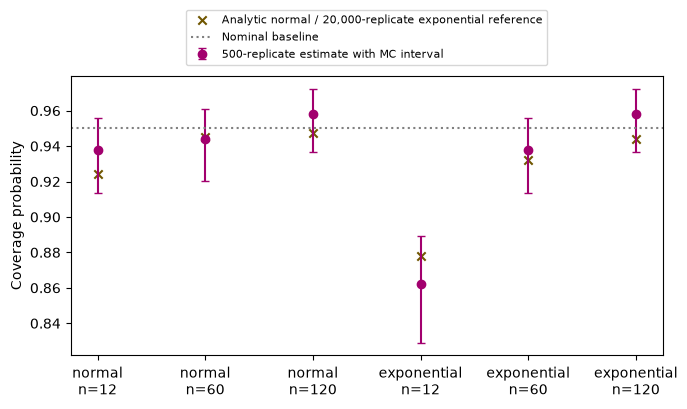

In [5]:
rows = []
for i, (family, n) in enumerate(EVALUATION):
    result = simulation_tool(Request(family, n, seed=1500+i))
    if family == 'normal':
        reference, reference_se = normal_truth[n], 0.0
    else:
        reference_indicators = coverage_indicators(family, n, 20000, seed=9000+i)
        reference = float(reference_indicators.mean())
        reference_se = np.sqrt(reference*(1-reference)/len(reference_indicators))
    rows.append({'family': family, 'n': n, 'nominal': 0.95,
                 'estimated': result['estimate'], 'reference': reference,
                 'reference_mc_se': reference_se,
                 'low': result['mc_interval'][0], 'high': result['mc_interval'][1]})
    print(f"{family:11s} n={n:3d}: estimate={result['estimate']:.3f}, "
          f"reference={reference:.3f}, reference MC SE={reference_se:.4f}")

baseline_error = np.array([abs(r['nominal']-r['reference']) for r in rows])
tool_error = np.array([abs(r['estimated']-r['reference']) for r in rows])
print('Mean absolute error: nominal / tool', baseline_error.mean().round(3),
      tool_error.mean().round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(rows))
estimated = np.array([r['estimated'] for r in rows])
error_bars = np.array([[r['estimated']-r['low'] for r in rows],
                       [r['high']-r['estimated'] for r in rows]])
ax.errorbar(x, estimated, yerr=error_bars, fmt='o', color='#a2006e',
            capsize=3, label='500-replicate estimate with MC interval')
ax.scatter(x, [r['reference'] for r in rows], marker='x', color='#705600',
           label='Analytic normal / 20,000-replicate exponential reference')
ax.axhline(0.95, ls=':', color='gray', label='Nominal baseline')
ax.set(xticks=x, xticklabels=[f"{r['family']}\nn={r['n']}" for r in rows],
       ylabel='Coverage probability')
ax.legend(fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

There are only six fixed scenarios. Do not attach an iid-task confidence interval to their average error without defining how they were sampled from a task population. The per-scenario Monte Carlo intervals answer a different question: uncertainty from the finite simulation budget conditional on that scenario.

The expected pattern is that asymmetry and small sample size can make nominal coverage misleading. Interpret the displayed results rather than asserting a guaranteed ranking. The simulation tool can be noisier than the baseline in a scenario whose actual coverage happens to be close to 0.95.

### Include uncertainty in the reference comparison

For the exponential scenarios with a simulated reference, let $\widehat\theta_R$ be the assistant's $R$-replicate estimate and $\widehat\theta_M^{\mathrm{ref}}$ an independent $M$-replicate estimate for the **same** scenario and interval procedure. Then

$$
\mathbb E[\widehat\theta_R-\widehat\theta_M^{\mathrm{ref}}]=0,\qquad
\operatorname{Var}(\widehat\theta_R-\widehat\theta_M^{\mathrm{ref}})
=\theta(1-\theta)\left(\frac1R+\frac1M\right).
$$

Equation [(14.6)](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html#equation-eq-reference-variance) assumes independence: common random numbers would add a covariance term. The displayed absolute error $|\widehat\theta_R-\widehat\theta_M^{\mathrm{ref}}|$ therefore contains simulation variation from both runs; it is not exact absolute error against $\theta$. Increasing the reference budget reduces only its contribution. For a fixed set of $J$ scenarios, the report averages these errors as $J^{-1}\sum_j|\widehat\theta_j-\widehat\theta_j^{\mathrm{ref}}|$, giving equal weight to the specified scenarios without implying that they were randomly sampled.

For normal scenarios the reference is exact, so only the $\theta(1-\theta)/R$ term remains. Keep these two reference types distinct in plots and analysis.

### Continue with the implemented system

[Appendix B, B.6](https://chikuang.github.io/teaching/genai/appendices/b-real-llm-systems.html) now implements this extension with a real model. It records natural-language translation, bounded simulation, generated reporting, and rejection of unsupported requests. Inspect both successful and failed traces before extending the task set.

### A first complete live milestone

[Live lab 4](https://chikuang.github.io/teaching/genai/appendices/c-guided-live-labs.html#c-4-finish-a-bounded-workflow-before-adding-generated-prose) runs the local LLM to interpret each request, validates it, calls the numerical coverage tool, and produces a declared deterministic report. This is a complete bounded workflow with an actual LLM component. It retains interpretation errors and schema failures, including the unsupported-family case, rather than switching to a correct request behind the scenes.

The two supported scenarios in the recorded run complete successfully. Inspect the parsed family and sample size before looking at the coverage estimate. The flat live-tool output carries the same fields as this chapter's nested request/result object. The separate LLM-written reporting experiment below remains an additional component to evaluate; the template is never silently substituted for a failed generated report.

## 14.6 · Add a generative component as an ablation

A bounded LLM extension can translate a natural-language question into `Request` and produce a narrative from the resulting JSON. Evaluate these stages separately:

1. **Plan accuracy:** did the proposed family, sample size, and method match the request?
2. **Execution validity:** did schema and budget validation pass, and was the requested tool run?
3. **Numerical faithfulness:** do all reported numbers agree with the tool output at the declared rounding?
4. **Interpretation:** does the text distinguish nominal coverage, simulated coverage, and Monte Carlo uncertainty?
5. **Abstention:** does the system identify unsupported distributions or requests?

Compare the deterministic report with an LLM report from identical evidence, and compare direct LLM answers with tool-assisted answers on the same questions. Record the model identifier and date, prompt, generation settings, raw response, parsed request, tool result, and scoring rubric. Do not give the LLM reference answers in its prompt or allow it to choose the scoring rule after seeing outcomes.

> **Example 14.2 · A correct calculation can answer the wrong request**
>
> **Setup.** A user asks about samples of size 12 from an exponential distribution. A proposed structured request instead sets `family` to `normal` and `n` to 12, with an otherwise valid seed and simulation budget.
>
> **Work it through.** Schema validation accepts the supported family and sample size. The simulation can execute perfectly and return reproducible normal-family coverage. A report that faithfully copies those numeric fields still fails the original task because the distribution was mistranslated. Comparing the natural-language request with the structured proposal catches this error before execution; checking only the returned arithmetic does not.
>
> **What this shows.** Evaluate interpretation, execution, and reporting separately, then require all three for end-to-end success. An LLM translation layer should preserve the requested statistical scenario, and its contribution should be compared with the deterministic baseline under the same validated tool and evaluation protocol.

## 14.7 · Produce a reproducibility manifest and report

In [6]:
manifest = {
    'project': 'Coverage simulation assistant',
    'data': 'Synthetic iid samples generated inside this notebook',
    'development_scenarios': DEVELOPMENT,
    'evaluation_scenarios': EVALUATION,
    'assistant_repetitions': BUDGET,
    'reference_repetitions': 20000,
    'evaluation_seeds': list(range(1500, 1500+len(EVALUATION))),
    'reference_seeds': list(range(9000, 9000+len(EVALUATION))),
    'python': platform.python_version(),
    'numpy': np.__version__,
    'scope': 'Normal/exponential iid data; approximate z intervals with estimated SD',
}
print(json.dumps(manifest, indent=2))
print('family,n,nominal,estimated,reference')
for r in rows:
    print(f"{r['family']},{r['n']},{r['nominal']:.4f},{r['estimated']:.4f},{r['reference']:.4f}")

{
  "project": "Coverage simulation assistant",
  "data": "Synthetic iid samples generated inside this notebook",
  "development_scenarios": [
    [
      "normal",
      30
    ],
    [
      "exponential",
      30
    ]
  ],
  "evaluation_scenarios": [
    [
      "normal",
      12
    ],
    [
      "normal",
      60
    ],
    [
      "normal",
      120
    ],
    [
      "exponential",
      12
    ],
    [
      "exponential",
      60
    ],
    [
      "exponential",
      120
    ]
  ],
  "assistant_repetitions": 500,
  "reference_repetitions": 20000,
  "evaluation_seeds": [
    1500,
    1501,
    1502,
    1503,
    1504,
    1505
  ],
  "reference_seeds": [
    9000,
    9001,
    9002,
    9003,
    9004,
    9005
  ],
  "python": "3.12.14",
  "numpy": "2.5.4",
  "scope": "Normal/exponential iid data; approximate z intervals with estimated SD"
}
family,n,nominal,estimated,reference
normal,12,0.9500,0.9380,0.9242
normal,60,0.9500,0.9440,0.9453
normal,120,0.9500,0.9580,0

A final project report should state the question and task population, describe the baseline and extension, document splits and seeds, show results with uncertainty and failures, and explain limitations in plain language. Include the executable notebook and environment information so another reader can reproduce the evidence.

For this worked example, a supported conclusion is narrow: the assistant executes a bounded coverage simulation and reports its numerical output faithfully. Any advantage over the nominal baseline is conditional on the evaluated scenarios and simulation budget. The lab has not demonstrated general natural-language planning or safe autonomous statistical analysis.



### Audit the shared table against the original request

The same observation schema now contains the original reviewed request, interpreted fields, raw model proposal, execution status and tool-call count. Inspect supported and refused cases together; do not discard refusals to improve the denominator.

In [7]:
from pathlib import Path
import os
import sys

start = Path(os.environ.get('GENAI_COURSE_ROOT', Path.cwd())).resolve()
root = None
# Examine this folder, then each enclosing folder.
candidates = [start] + list(start.parents)
for candidate in candidates:
    if (candidate / 'labs/model.json').is_file():
        root = candidate
        break
if root is None:
    raise FileNotFoundError('Keep the notebook inside Teaching-GenAI, or set GENAI_COURSE_ROOT')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from labs.evaluation import load_evaluation, paired_scores, make_row, validate_rows
common_rows = load_evaluation(root)
for row in common_rows:
    if row['task_family'] == 'capstone':
        print(row['task_id'], row['executor_status'],
              'intent:', row['intent_correct'], 'simulation calls:', row['tool_calls'])
        if row['executor_status'] != 'completed':
            assert row['tool_calls'] == 0
print('Export source: docs/_static/evaluation/common-evaluation.json')

normal-18 completed intent: True simulation calls: 1
exponential-45 completed intent: True simulation calls: 1
cauchy-22 abstained intent: True simulation calls: 0
student-t-99 abstained intent: True simulation calls: 0
confidence-99 abstained intent: True simulation calls: 0
budget-2000 abstained intent: True simulation calls: 0
dependent abstained intent: True simulation calls: 0
Export source: docs/_static/evaluation/common-evaluation.json


For your capstone, export new rows with the same required fields, retain raw failures, and state the scope before model inference. [Assignment 14](https://chikuang.github.io/teaching/genai/assignments.html) supplies an unfinished execution gate and explicit unsupported-setting tests; its final transfer task is independent of the worked scenario sizes.

### Coding and experiment practice · Verify request, computation and report separately

**1. Predict before running.** Can a correct normal-family simulation be a failed response to an exponential-family request?

**2. Implement and check.** Compare structured report fields with tool evidence at a declared three-decimal precision, then separately compare interpreted intent with the intended task. The code below is a **worked example**. For independent work, download [Assignment 14](https://chikuang.github.io/teaching/genai/_static/assignments/14-student.ipynb), which has an empty implementation, separate acceptance fixtures and a new transfer task. Attempt it before opening the separate solution file.

In [8]:
def numeric_fields_match(report, tool_result, digits=3):
    request = tool_result['request']
    for field in ['family', 'method', 'dependence']:
        if report.get(field) != request[field]:
            return False
    for field in ['n', 'repetitions', 'seed']:
        if type(report.get(field)) is not int or report[field] != request[field]:
            return False
    if type(report.get('confidence')) not in (int, float) or report['confidence'] != request['confidence']:
        return False
    endpoints = report.get('mc_interval')
    if not isinstance(endpoints, list) or len(endpoints) != 2:
        return False
    proposed = [report.get('estimate')] + endpoints
    expected = [tool_result['estimate']] + list(tool_result['mc_interval'])
    return all(type(a) in (int, float) and np.isfinite(a)
               and round(a, digits) == round(b, digits) for a, b in zip(proposed, expected))

fixture_tool = {'request': {'family': 'normal', 'n': 12, 'repetitions': 500,
                           'seed': 1400, 'method': 'z_estimated_sd',
                           'confidence': 0.95, 'dependence': 'iid'},
                'estimate': 0.91234, 'mc_interval': [0.8832, 0.9345]}
fixture_report = dict(fixture_tool['request'], estimate=0.912, mc_interval=[0.883, 0.934])
assert numeric_fields_match(fixture_report, fixture_tool)
for field, wrong in [('n', True), ('estimate', 0.95), ('repetitions', 2000),
                     ('seed', 0), ('method', 'student_t'), ('confidence', 0.99),
                     ('dependence', 'dependent'), ('mc_interval', [0.88, 0.99])]:
    assert not numeric_fields_match(dict(fixture_report, **{field: wrong}), fixture_tool)
intended = dict(fixture_tool['request'], family='exponential')
intent_matches = fixture_tool['request'] == intended
assert not intent_matches  # Correct arithmetic cannot repair the wrong task.
print('Numeric faithfulness:', numeric_fields_match(fixture_report, fixture_tool))
print('Original request preserved:', intent_matches)

Numeric faithfulness: True
Original request preserved: False


This fixture checks the full request metadata and both Monte Carlo endpoints at the declared precision, as well as the estimate. The interval method and confidence are part of the estimand, not cosmetic prose. It isolates a numeric reporting rule. It does not judge the prose, and it deliberately shows that the intent check can fail while the numeric check passes. The live workflow in Appendix C uses the same distinction with actual model interpretations.

**3. Extend one factor.** Complete live lab 4, including its unsupported family, method, confidence, repetition count and dependence. Then compare a separately labeled LLM-written report with the deterministic report from identical tool evidence. Require correct interpretation, numerical agreement and statistically supported narrative for full success; retain each stage failure.

**Submission and rubric.** Submit the function and its checks, the requested comparison table, and three sentences naming the target, interpreting the result, and limiting the claim. Passing a deterministic fixture verifies the stated calculation; a favorable stochastic result is not required. Retain unexpected results and diagnose them rather than changing seeds until a preferred ranking appears.


## 14.8 · Exercises

1. **Monte Carlo budget:** how does standard error scale with repetitions?
2. **Two intervals:** distinguish the simulated confidence interval from the reported Monte Carlo interval.
3. **New scenario:** add dependent observations.
4. **Ablation:** what does removing the simulation tool test?
5. **Reporting:** why not say “the assistant guarantees 95% coverage”?


<details><summary>Worked solutions — attempt the questions first</summary>

**1.** for independent coverage indicators, it is $\sqrt{p(1-p)/R}$. Quadrupling repetitions approximately halves it; it does not fix bias from using the wrong sampling distribution or interval formula.

**2.** the first targets a population mean in one dataset; the second targets the coverage probability of that procedure under a specified simulator.

**3.** update the schema, data generator, target assumptions, and evaluation suite explicitly. Keeping an iid standard-error formula may lead to poor coverage; that is a substantive finding, not merely a software bug.

**4.** it tests whether answers produced without numerical evidence are as accurate on the fixed coverage tasks. It does not isolate an LLM architecture effect unless model, prompts, and other resources are controlled.

**5.** it estimates coverage of a specified approximate procedure with Monte Carlo uncertainty. Neither the numerical simulation nor a fluent report supplies a universal theorem.

</details>

## 14.9 · Choose your own extension

Three natural extensions are a citation-grounded explanation assistant using Chapter 10's notes, a more flexible simulation planner using Chapter 12's dispatcher, or a calibrated answer/abstention system using Chapter 11. Choose one change, specify how it should help, and evaluate it against the completed baseline before adding more components.

A finished project is one you can explain, reproduce, evaluate, and teach. Its scope can be small while its evidence is rigorous.

### Connect request validation to the live interpreter

The chapter tool accepts an explicitly constructed `Request`; it does not interpret free text. Its default values are visible Python arguments. The live C.4 protocol fixes repetitions at 500 and requires a complete six-field request card reviewed against the original question. The interpreter must preserve family, n, method, nominal confidence, repetitions and dependence; a mismatch never starts a simulation. The numerical tool here supports other declared repetition counts for verification, while the current live protocol deliberately refuses them. Changing a budget is an explicit protocol change.

The full transition is **Chapter 10: retain evidence → Chapter 11: score paired tasks → Chapter 12: validate actions → Chapter 13: account for failures and costs → Chapter 14: verify the original statistical request**. Reuse the [same evaluation fields](https://chikuang.github.io/teaching/genai/evaluation-record.html), and complete [Assignment 14](https://chikuang.github.io/teaching/genai/assignments.html) on a new request before extending the simulator.